
# Real-time Face Recognition using MTCNN and FaceNet

## 1. Introduction

### 1.1. Project Overview

This project implements a real-time face recognition system using OpenCV, MTCNN, and FaceNet.

The system detects faces from webcam frames, aligns detected faces, extracts facial embeddings, and compares them with a registered reference face using cosine similarity.

### 1.2. Objectives

- Detect faces using MTCNN.
- Align faces based on facial landmarks.
- Extract 128-dimensional facial embeddings using FaceNet.
- Compare embeddings using cosine similarity.
- Classify faces as Matched or Unknown using a threshold of 0.7.
- Evaluate recognition performance under different face occlusion conditions.

### 1.3. Recognition Pipeline

Input Image / Webcam Frame

→ MTCNN Face Detection

→ Face Alignment

→ FaceNet Feature Extraction (128D)

→ Cosine Similarity

→ Matched / Unknown

### 1.4. Evaluation Scope

The notebook evaluates:

1. Face detection and facial landmarks.
2. Face alignment.
3. Face embedding extraction.
4. Cosine similarity-based matching.
5. Recognition under eye occlusion.
6. Comparison between alignment and no alignment.


## 2. Environment and Dataset

### 2.1. Environment Setup

This section initializes the project environment, imports the required
libraries, and verifies that the notebook can access the project's
source modules.

The notebook reuses the existing implementation in `src/` rather than
reimplementing the face recognition algorithms.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [3]:
# Standard library
import sys
from pathlib import Path

# Third-party libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Project modules
from src.config import REFERENCE_PATH, SIMILARITY_THRESHOLD
from src.face_detector import FaceDetector
from src.face_alignment import align_face
from src.face_embedder import FaceEmbedder
from src.face_matcher import FaceMatcher
from src.visualizer import draw_results


### 2.2. Dataset Preparation

The evaluation dataset consists of one reference image and two test images.

| Image | Purpose |
|---|---|
| `my_face.jpg` | Reference image used to register the target identity |
| `normal.jpg` | Test image without facial occlusion |
| `eye_occlusion.jpg` | Test image with eyes and upper nose covered |

All images are loaded using OpenCV in BGR format. They are converted to RGB only for visualization with Matplotlib.

The same test images will be used in subsequent experiments to ensure a consistent comparison.


In [4]:
IMAGE_PATHS = {
    "Reference": ROOT / REFERENCE_PATH,
    "Normal": ROOT / "data/evaluation/normal.jpg",
    "Eye Occlusion": ROOT / "data/evaluation/eye_occlusion.jpg",
}

for name, path in IMAGE_PATHS.items():
    assert path.is_file(), f"Image not found: {path}"
    print(f"{name}: FOUND")

Reference: FOUND
Normal: FOUND
Eye Occlusion: FOUND


In [5]:
# Nạp ảnh
images = {}

for name, path in IMAGE_PATHS.items():
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Failed to load image: {path}")

    images[name] = image

    print(f"{name}: shape={image.shape}, dtype={image.dtype}")

Reference: shape=(2560, 1440, 3), dtype=uint8
Normal: shape=(2560, 1440, 3), dtype=uint8
Eye Occlusion: shape=(2560, 1440, 3), dtype=uint8


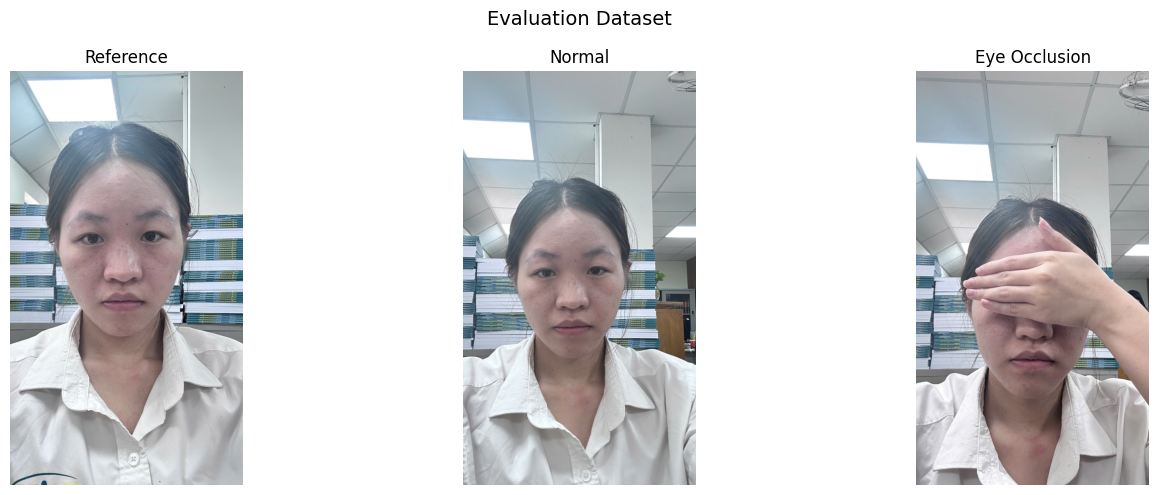

In [6]:
# Trực quan hóa ảnh đầu vào
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, image) in zip(axes, images.items()):
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(rgb_image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Evaluation Dataset", fontsize=14)
plt.tight_layout()
plt.show()


**Observation:**

All three images were loaded successfully. The dataset includes a reference face, a normal test condition, and an eye-occlusion condition. These images provide the inputs for the subsequent face detection and recognition experiments.



## 3. Face Detection using MTCNN

### 3.1. Method

MTCNN (Multi-task Cascaded Convolutional Networks) is used to detect faces and localize facial landmarks.

The detector produces three main outputs:

- **Bounding box:** The location of a detected face, represented as `(x, y, width, height)`.
- **Confidence score:** The detector's confidence in the face detection.
- **Facial landmarks:** Five keypoints corresponding to the left eye, right eye, nose, left mouth corner, and right mouth corner.

These outputs are used for face localization and subsequent face alignment.

### 3.2. Experimental Objective

Apply the existing `FaceDetector` module to the reference, normal, and eye-occlusion images.

The experiment examines whether MTCNN can detect a face and estimate facial landmarks under different visibility conditions.


In [8]:
detector = FaceDetector()

detection_results = {}

for name, image in images.items():
    faces = detector.detect(image)
    detection_results[name] = faces

    print(f"\n{name}: {len(faces)} face(s) detected")

    for i, face in enumerate(faces):
        print(f"  Face {i + 1}")
        print(f"  Box: {face['box']}")
        print(f"  Confidence: {face['confidence']:.4f}")
        print(f"  Keypoints: {face['keypoints']}")

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "c:\Users\NAO\Downloads\lab5_face_ID\.venv\Lib\site-packages\lz4\frame\__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "c:\Users\NAO\Downloads\lab5_face_ID\.venv\Lib\site-packages\lz4\frame\__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "c:\Users\NAO\Downloads\lab5_face_ID\.venv\Lib\site-packages\lz4\frame\__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.



Reference: 1 face(s) detected
  Face 1
  Box: [314, 636, 736, 971]
  Confidence: 0.9988
  Keypoints: {'nose': [np.int64(691), np.int64(1256)], 'mouth_right': [np.int64(833), np.int64(1400)], 'right_eye': [np.int64(872), np.int64(1022)], 'left_eye': [np.int64(507), np.int64(1037)], 'mouth_left': [np.int64(557), np.int64(1411)]}

Normal: 1 face(s) detected
  Face 1
  Box: [327, 896, 643, 874]
  Confidence: 0.9999
  Keypoints: {'nose': [np.int64(681), np.int64(1437)], 'mouth_right': [np.int64(798), np.int64(1568)], 'right_eye': [np.int64(817), np.int64(1239)], 'left_eye': [np.int64(519), np.int64(1251)], 'mouth_left': [np.int64(556), np.int64(1572)]}

Eye Occlusion: 1 face(s) detected
  Face 1
  Box: [398, 1239, 669, 784]
  Confidence: 0.8155
  Keypoints: {'nose': [np.int64(803), np.int64(1659)], 'mouth_right': [np.int64(865), np.int64(1810)], 'right_eye': [np.int64(931), np.int64(1505)], 'left_eye': [np.int64(640), np.int64(1492)], 'mouth_left': [np.int64(599), np.int64(1786)]}


3.3. Experimental Results

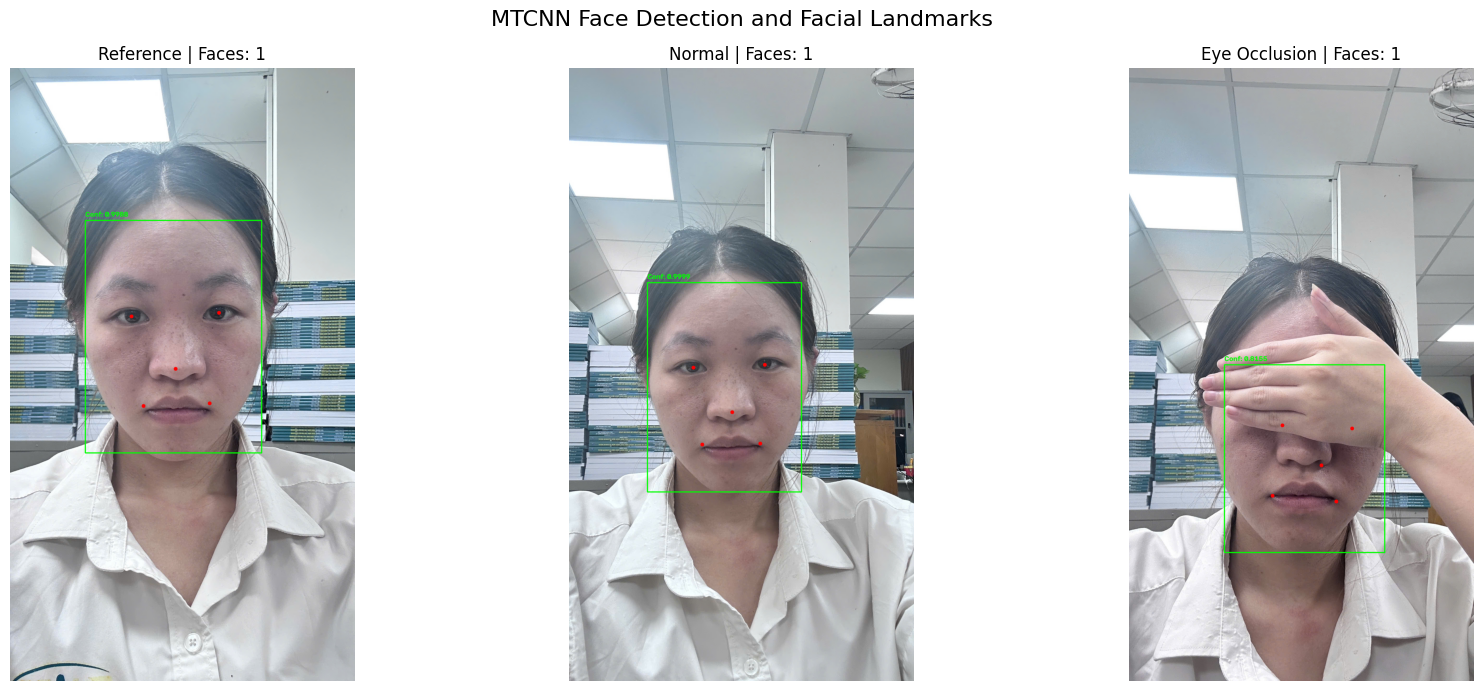

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (name, image) in zip(axes, images.items()):
    display = image.copy()

    for face in detection_results[name]:
        x, y, w, h = map(int, face["box"])
        confidence = float(face["confidence"])

        # Bounding box
        cv2.rectangle(
            display,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

        # Detection confidence
        cv2.putText(
            display,
            f"Conf: {confidence:.4f}",
            (x, max(y - 15, 30)),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            3
        )

        # Five facial landmarks
        for point in face["keypoints"].values():
            px, py = map(int, point)
            cv2.circle(display, (px, py), 8, (0, 0, 255), -1)

    display_rgb = cv2.cvtColor(display, cv2.COLOR_BGR2RGB)

    ax.imshow(display_rgb)
    ax.set_title(
        f"{name} | Faces: {len(detection_results[name])}"
    )
    ax.axis("off")

plt.suptitle("MTCNN Face Detection and Facial Landmarks", fontsize=16)
plt.tight_layout()
plt.show()

### 3.4. Experimental Discussion

The MTCNN detector successfully detected one face in each of the three evaluation images.

The reference image achieved a detection confidence of **0.9988**, while the normal test image achieved **0.9999**. Under eye occlusion, the detection confidence decreased to **0.8155**.

This result suggests that occlusion around the eye region can reduce the detector's confidence. Nevertheless, MTCNN was still able to localize the face and estimate five facial landmarks in the occluded image.

These observations demonstrate successful face detection on the three selected samples. However, the results do not establish the detector's general accuracy or the correctness of the subsequent identity recognition process.


## 4. Face Alignment

### 4.1. Method

Face alignment is a geometric preprocessing technique that reduces variations caused by head rotation.

In this project, facial alignment is performed using the left-eye and right-eye landmarks detected by MTCNN.

The alignment procedure consists of:

1. Extracting the two eye coordinates.
2. Calculating the angle between the eyes.
3. Rotating the image to compensate for head tilt.
4. Cropping the aligned face region.

The resulting face image is used as input to the FaceNet embedding extractor.

### 4.2. Experimental Objective

Visualize the face region before and after alignment for three evaluation images:

- Reference
- Normal
- Eye Occlusion

The experiment examines the visual effect of alignment and the quality of the resulting face crops.


In [10]:
aligned_faces = {}
original_faces = {}

for name, image in images.items():
    faces = detection_results[name]

    if len(faces) == 0:
        print(f"{name}: No face detected")
        continue

    # Chọn khuôn mặt có confidence cao nhất
    face = max(faces, key=lambda f: f["confidence"])

    x, y, w, h = map(int, face["box"])

    # Giới hạn tọa độ trong kích thước ảnh
    height, width = image.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)

    original_crop = image[y1:y2, x1:x2].copy()

    # Gọi module alignment của project
    aligned_crop = align_face(image, face)

    if original_crop.size == 0 or aligned_crop is None or aligned_crop.size == 0:
        print(f"{name}: Invalid face crop")
        continue

    original_faces[name] = original_crop
    aligned_faces[name] = aligned_crop

    print(f"{name}")
    print(f"  Original shape: {original_crop.shape}")
    print(f"  Aligned shape:  {aligned_crop.shape}")

Reference
  Original shape: (971, 736, 3)
  Aligned shape:  (1002, 776, 3)
Normal
  Original shape: (874, 643, 3)
  Aligned shape:  (900, 678, 3)
Eye Occlusion
  Original shape: (784, 669, 3)
  Aligned shape:  (814, 705, 3)


### 4.3. Visualization

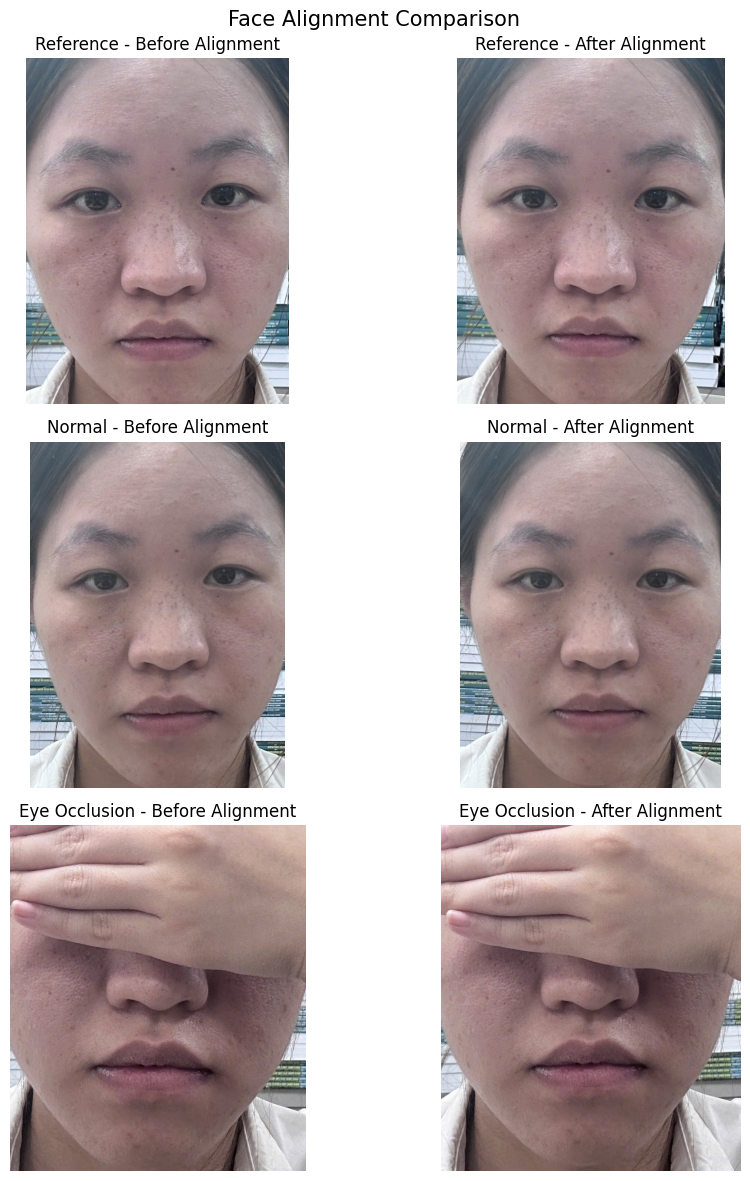

In [11]:
names = list(aligned_faces.keys())

fig, axes = plt.subplots(
    len(names), 2,
    figsize=(10, 4 * len(names)),
    squeeze=False
)

for i, name in enumerate(names):
    before = original_faces[name]
    after = aligned_faces[name]

    axes[i, 0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{name} - Before Alignment")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{name} - After Alignment")
    axes[i, 1].axis("off")

plt.suptitle("Face Alignment Comparison", fontsize=15)
plt.tight_layout()
plt.show()

### 4.4. Kiểm tra góc nghiêng hai mắt

In [12]:
angles = {}

for name, faces in detection_results.items():
    if not faces:
        continue

    face = max(faces, key=lambda f: f["confidence"])

    left_eye = np.array(face["keypoints"]["left_eye"], dtype=float)
    right_eye = np.array(face["keypoints"]["right_eye"], dtype=float)

    dx = right_eye[0] - left_eye[0]
    dy = right_eye[1] - left_eye[1]

    angle = np.degrees(np.arctan2(dy, dx))
    angles[name] = angle

    print(f"{name}: Eye-line angle = {angle:.2f} degrees")

Reference: Eye-line angle = -2.35 degrees
Normal: Eye-line angle = -2.31 degrees
Eye Occlusion: Eye-line angle = 2.56 degrees



### 4.5. Experimental Discussion

The alignment procedure was applied to the detected faces using the eye landmarks provided by MTCNN.

The visualization compares the original face crops with the aligned face crops for the reference, normal, and eye-occlusion conditions.

The estimated eye-line angles provide information about the initial facial tilt. However, these values alone do not establish whether alignment improves recognition performance.

The effect of alignment on FaceNet similarity will be examined in the subsequent ablation experiment.



## 5. Face Embedding using FaceNet

### 5.1. Method

Face embedding is the process of transforming a facial image into a numerical feature vector.

In this project, a pretrained FaceNet model is used to extract a 128-dimensional embedding from each aligned face.

The existing `FaceEmbedder` module handles the model inference and preprocessing.

### 5.2. Experimental Objective

The experiment aims to:

1. Extract embeddings from the three aligned face images.
2. Verify the dimensionality and numerical validity of the embeddings.
3. Visualize the distribution of embedding values.

The similarity between different embeddings will be evaluated in Section 6.


In [13]:
embedder = FaceEmbedder()

embeddings = {}

for name, face_image in aligned_faces.items():
    embedding = embedder.extract(face_image)

    embeddings[name] = embedding

    print(f"\n{name}")
    print(f"  Shape: {embedding.shape}")
    print(f"  Dtype: {embedding.dtype}")
    print(f"  L2 norm: {np.linalg.norm(embedding):.4f}")
    print(f"  First 5 values: {embedding[:5]}")


Reference
  Shape: (128,)
  Dtype: float32
  L2 norm: 8.6915
  First 5 values: [ 0.42758325 -1.2639611   0.49084148 -1.6858733  -0.33597255]

Normal
  Shape: (128,)
  Dtype: float32
  L2 norm: 8.0260
  First 5 values: [ 0.37965366 -1.1584226   0.23644948 -1.4780127  -0.50686514]

Eye Occlusion
  Shape: (128,)
  Dtype: float32
  L2 norm: 11.2038
  First 5 values: [-0.94403803 -0.92107177 -0.9586221  -0.1587789   0.23638156]


In [14]:
for name, embedding in embeddings.items():
    assert embedding.shape == (128,), f"{name}: Invalid embedding shape"
    assert np.all(np.isfinite(embedding)), f"{name}: Non-finite values"

    print(f"{name}: PASS")

Reference: PASS
Normal: PASS
Eye Occlusion: PASS


5.3. Visualization — Biểu diễn vector đặc trưng

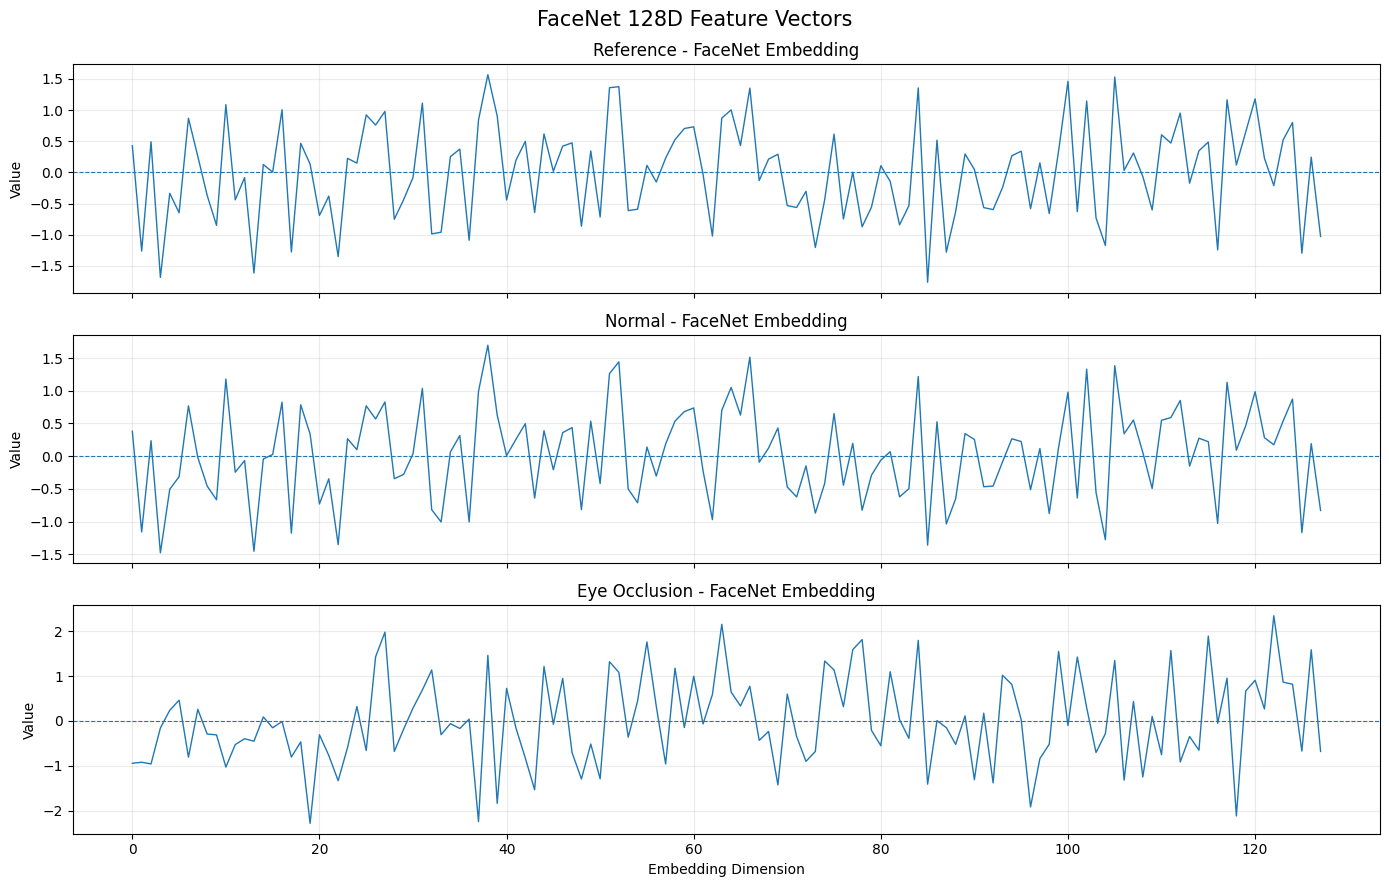

In [15]:
fig, axes = plt.subplots(
    len(embeddings), 1,
    figsize=(14, 9),
    sharex=True,
    squeeze=False
)

for ax, (name, embedding) in zip(axes.flat, embeddings.items()):
    ax.plot(np.arange(128), embedding, linewidth=1)
    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set_title(f"{name} - FaceNet Embedding")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.25)

axes[-1, 0].set_xlabel("Embedding Dimension")
plt.suptitle("FaceNet 128D Feature Vectors", fontsize=15)
plt.tight_layout()
plt.show()


### 5.4. Experimental Discussion

FaceNet embeddings were extracted from the aligned face images.

Each embedding is expected to contain 128 numerical features representing the input face in a learned feature space.

The visualization illustrates the variation of embedding values across dimensions. However, individual embedding dimensions do not have directly interpretable semantic meanings.

To evaluate facial identity similarity, the embeddings must be compared using an appropriate similarity metric, such as cosine similarity.



## 6. Face Matching using Cosine Similarity

### 6.1. Method

Face matching compares facial embeddings to estimate the similarity between two face images.

This project uses cosine similarity, which measures the cosine of the angle between two embedding vectors.

The reference embedding is compared against the normal and eye-occlusion embeddings.

A similarity threshold of 0.7 is used:

- Similarity >= 0.7: Matched
- Similarity < 0.7: Unknown

The threshold is a predefined project configuration rather than an experimentally optimized value.

### 6.2. Experimental Objective

1. Calculate cosine similarity between the reference and test embeddings.
2. Apply the predefined decision threshold.
3. Visualize the similarity scores.
4. Analyze the effect of eye occlusion on face recognition.


In [16]:
reference_embedding = embeddings["Reference"]

similarity_results = {}

for name in ["Normal", "Eye Occlusion"]:
    test_embedding = embeddings[name]

    similarity = np.dot(reference_embedding, test_embedding) / (
        np.linalg.norm(reference_embedding)
        * np.linalg.norm(test_embedding)
    )

    similarity = float(similarity)

    label = (
        "Matched"
        if similarity >= SIMILARITY_THRESHOLD
        else "Unknown"
    )

    similarity_results[name] = {
        "similarity": similarity,
        "label": label
    }

    print(f"{name}")
    print(f"  Cosine Similarity: {similarity:.4f}")
    print(f"  Prediction: {label}")

Normal
  Cosine Similarity: 0.9765
  Prediction: Matched
Eye Occlusion
  Cosine Similarity: 0.2971
  Prediction: Unknown


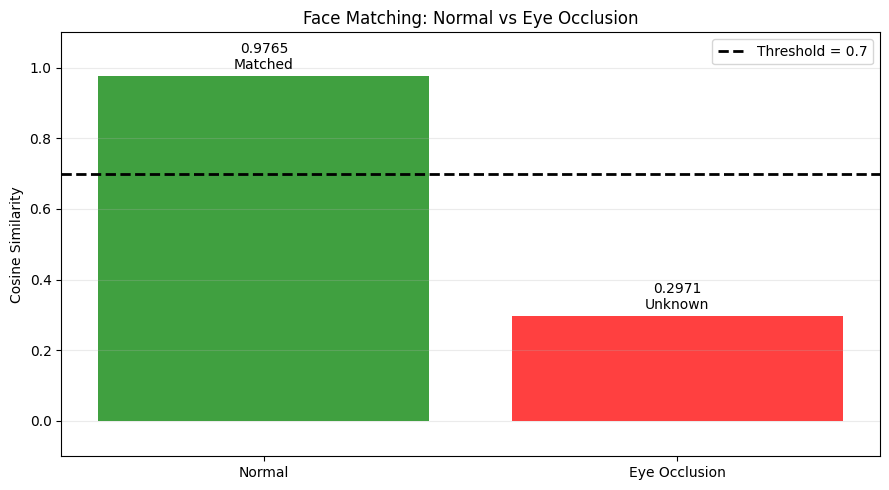

In [17]:
names = list(similarity_results.keys())

scores = [
    similarity_results[name]["similarity"]
    for name in names
]

labels = [
    similarity_results[name]["label"]
    for name in names
]

colors = [
    "green" if label == "Matched" else "red"
    for label in labels
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(names, scores, color=colors, alpha=0.75)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

for bar, score, label in zip(bars, scores, labels):
    ax.annotate(
        f"{score:.4f}\n{label}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylabel("Cosine Similarity")
ax.set_title("Face Matching: Normal vs Eye Occlusion")
ax.set_ylim(min(-0.1, min(scores) - 0.15), 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 6.3. Experimental Discussion

The normal test image achieved a cosine similarity of **0.9765**, exceeding the predefined threshold of 0.7. The system correctly classified this image as *Matched*.

In contrast, the eye-occlusion image achieved a similarity of **0.2971**, resulting in an *Unknown* classification. Since both test images belong to the registered identity, this outcome represents a false rejection.

The substantial decrease in similarity suggests that occlusion around the eye region affects the facial representation produced by the recognition pipeline.

Although MTCNN successfully detected the occluded face, successful detection did not guarantee successful identity recognition.

These results are limited to the selected evaluation images and should not be interpreted as general recognition accuracy.


## 7. Ablation Study: Effect of Face Alignment

### 7.1. Experimental Design

An ablation study is conducted to investigate the contribution of face alignment to recognition performance.

Two configurations are compared:

- **With Alignment:** Face detection → Face alignment → FaceNet → Cosine similarity.
- **Without Alignment:** Face detection → Face cropping → FaceNet → Cosine similarity.

Both configurations use the same reference identity, test images, FaceNet model, and similarity threshold of 0.7.

The reference and test embeddings are generated using the same preprocessing configuration within each experiment.

### 7.2. Experimental Objective

The experiment aims to determine whether face alignment increases cosine similarity for the selected normal and eye-occlusion images.


In [18]:
embeddings_no_alignment = {}

for name, face_image in original_faces.items():
    embedding = embedder.extract(face_image)

    assert embedding.shape == (128,)
    assert np.all(np.isfinite(embedding))

    embeddings_no_alignment[name] = embedding

    print(f"{name}: {embedding.shape} - PASS")

Reference: (128,) - PASS
Normal: (128,) - PASS
Eye Occlusion: (128,) - PASS


In [19]:
ablation_results = {}

for name in ["Normal", "Eye Occlusion"]:
    # With alignment: kết quả từ Section 6
    sim_aligned = similarity_results[name]["similarity"]

    # Without alignment
    ref = embeddings_no_alignment["Reference"]
    test = embeddings_no_alignment[name]

    sim_no_alignment = float(
        np.dot(ref, test)
        / (np.linalg.norm(ref) * np.linalg.norm(test))
    )

    ablation_results[name] = {
        "With Alignment": sim_aligned,
        "Without Alignment": sim_no_alignment,
        "Difference": sim_aligned - sim_no_alignment
    }

    print(f"\n{name}")
    print(f"  With Alignment:    {sim_aligned:.4f}")
    print(f"  Without Alignment: {sim_no_alignment:.4f}")
    print(f"  Difference:        {sim_aligned - sim_no_alignment:+.4f}")


Normal
  With Alignment:    0.9765
  Without Alignment: 0.9875
  Difference:        -0.0110

Eye Occlusion
  With Alignment:    0.2971
  Without Alignment: 0.2868
  Difference:        +0.0103


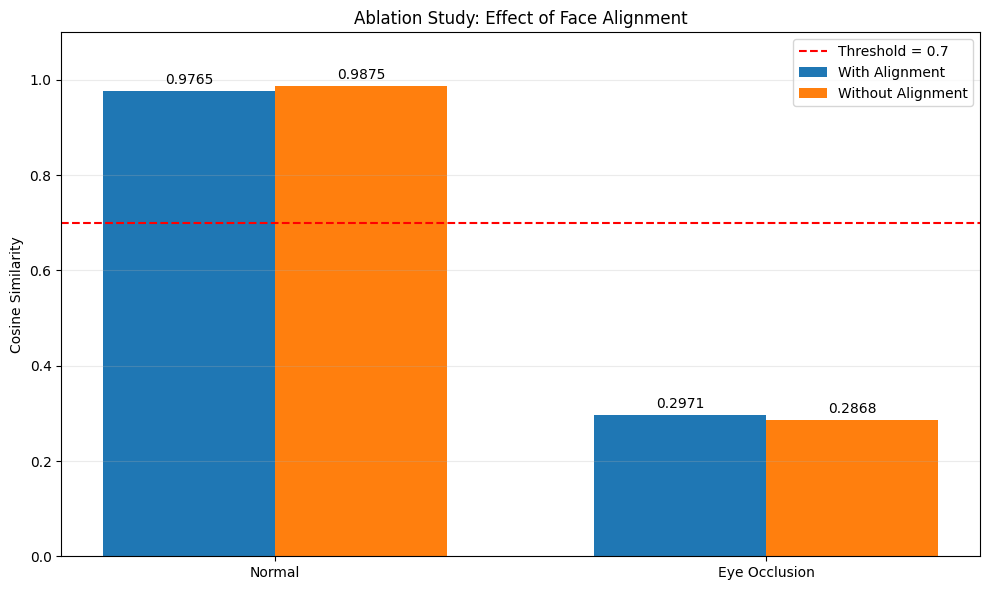

In [20]:
names = list(ablation_results.keys())

with_alignment = [
    ablation_results[name]["With Alignment"]
    for name in names
]

without_alignment = [
    ablation_results[name]["Without Alignment"]
    for name in names
]

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    with_alignment,
    width,
    label="With Alignment"
)

bars2 = ax.bar(
    x + width / 2,
    without_alignment,
    width,
    label="Without Alignment"
)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="red",
    linestyle="--",
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Cosine Similarity")
ax.set_title("Ablation Study: Effect of Face Alignment")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 7.3. Experimental Results and Discussion

The ablation study compared face recognition performance with and without face alignment using the same reference and evaluation images.

For the normal image, cosine similarity decreased from **0.9875 without alignment** to **0.9765 with alignment**, representing a difference of −0.0110.

For the eye-occlusion image, cosine similarity increased from **0.2868 without alignment** to **0.2971 with alignment**, representing a difference of +0.0103.

Despite these differences, both configurations produced identical classification outcomes at the predefined threshold of 0.7. The normal image was classified as *Matched*, whereas the eye-occlusion image was classified as *Unknown*.

These results indicate that face alignment did not consistently improve similarity scores for the selected samples. Furthermore, alignment was insufficient to overcome the recognition failure caused by eye occlusion.

Because the experiment uses only two test images, the findings cannot establish whether face alignment generally improves or reduces recognition performance. The comparison also reflects differences in face cropping introduced by the current alignment implementation.


## 8. Overall Evaluation and Conclusion

### 8.1. Overall Evaluation

The evaluation covers the following components:

1. Face Detection using MTCNN.
2. Face Alignment using eye landmarks.
3. Face Embedding using pretrained FaceNet.
4. Face Matching using cosine similarity.
5. Ablation Study comparing alignment and no alignment.

The experiments use one reference image and two test images representing normal and eye-occlusion conditions.


In [22]:
import pandas as pd
from IPython.display import display as show_table

summary_rows = []

for name in ["Normal", "Eye Occlusion"]:
    similarity = similarity_results[name]["similarity"]
    prediction = similarity_results[name]["label"]

    summary_rows.append({
        "Test Image": name,
        "Detection Confidence": max(
            face["confidence"]
            for face in detection_results[name]
        ),
        "Similarity (Aligned)": similarity,
        "Similarity (No Alignment)": ablation_results[name]["Without Alignment"],
        "Prediction": prediction,
        "Expected": "Matched",
        "Correct": prediction == "Matched"
    })

summary_df = pd.DataFrame(summary_rows)

show_table(summary_df.round(4))

,Test Image,Detection Confidence,Similarity (Aligned),Similarity (No Alignment),Prediction,Expected,Correct
0,Normal,0.9999,0.9765,0.9875,Matched,Matched,True
1,Eye Occlusion,0.8155,0.2971,0.2868,Unknown,Matched,False


### 8.3. Limitations

The experimental evaluation has several limitations:

- The dataset contains only one reference image and two test images from the same identity.
- The experiment does not include an independent stranger test image, so false acceptance behavior has not been evaluated in this notebook.
- The similarity threshold of 0.7 has not been optimized using a validation dataset.
- The effect of face alignment is evaluated on a limited number of samples.
- Recognition performance under different lighting conditions, head poses, camera distances, and occlusion patterns has not been systematically measured.

Therefore, the observed results should be interpreted as a small-scale case study rather than a general estimate of recognition accuracy.

### 8.4. Conclusion

This project successfully implemented a face recognition pipeline combining MTCNN face detection, landmark-based face alignment, pretrained FaceNet embedding extraction, and cosine similarity matching.

MTCNN detected faces in all three evaluation images. FaceNet successfully extracted 128-dimensional embeddings from the detected faces.

The normal test image was correctly recognized, achieving a cosine similarity of **0.9765** with alignment. However, the eye-occlusion image produced a substantially lower similarity of **0.2971**, resulting in a false rejection.

The ablation study showed that face alignment did not consistently improve similarity scores for the selected samples and did not change the final classification outcomes.

Overall, the experiment demonstrates the functionality of the proposed recognition pipeline while highlighting its sensitivity to occlusion around the eye region.

### 8.5. Future Work

Future experiments should evaluate a larger dataset containing multiple identities and a wider range of environmental conditions.

Recognition performance could be assessed using false acceptance rate (FAR), false rejection rate (FRR), and threshold-dependent evaluation. Additional experiments could investigate more robust face alignment and alternative face embedding models.